## 线性回归概念
利用回归方程（函数）对一个或者多个自变量（特征值）和因变量（目标值）之间的关系进行建模的一种分析方式。

- **一元线性回归**：目标值只与一个特征值有关  
- **多元线性回归**：目标值与多个特征值有关  

参数：**权重（weight）**、**偏置（bias）**

$$
y = wx + b \quad \text{（一元）}
$$

$$
y = w_{1}x_{1} + w_{2}x_{2} + \cdots + w_{n}x_{n} + b \quad \text{（多元）}
$$

**多元线性回归的矩阵形式（标准）：**
$$
y = \mathbf{w}^T \mathbf{x} + b
= \begin{bmatrix} w_1 & w_2 & \cdots & w_n \end{bmatrix}
  \begin{bmatrix} x_1 \\ x_2 \\ \vdots \\ x_n \end{bmatrix}
+ b
$$

**增广形式（将偏置吸收进向量）：**
$$
y = \tilde{\mathbf{w}}^T \tilde{\mathbf{x}}
= 
\begin{bmatrix}
w_1 \\
w_2 \\
\vdots \\
w_n \\
b
\end{bmatrix}^T
\cdot
\begin{bmatrix}
x_1 \\
x_2 \\
\vdots \\
x_n \\
1
\end{bmatrix}
$$

## 损失函数（Loss Function）

> 也称：**成本函数（Cost Function）**、**代价函数**、**目标函数（Objective Function）**  
> 作用：衡量**模型预测值**与**真实值**之间的差异程度。损失函数值越小，说明模型拟合效果越好。

**基本定义**：  
对于单个样本，定义误差（Error）为：
$$
\text{误差} = \text{预测值} - \text{真实值}
$$

但单纯求和会正负抵消，因此常用**平方**或**绝对值**来度量。

---

### 1. 均方误差（MSE，Mean Squared Error）

**定义**：计算所有样本的误差平方和的平均值。  即最小二乘 / 样本个数

**公式**：
$$
\text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2
$$

- **\( n \)**：样本总数  
- **\( y_i \)**：第 \( i \) 个样本的真实值  
- **\( \hat{y}_i \)**：第 \( i \) 个样本的预测值

**特点**：
- 对较大误差（离群点）非常敏感（因为平方放大了误差）
- 可导，便于使用梯度下降等优化算法
- 常用于线性回归的优化目标

---

### 2. 平均绝对误差（MAE，Mean Absolute Error）

**定义**：计算所有样本的误差绝对值和的平均值。

**公式**：
$$
\text{MAE} = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|
$$

**特点**：
- 对离群点相对不敏感（因为只取绝对值）
- 鲁棒性更好，但不可导（在零点不可导）
- 常用于需要稳健估计的场景

---

### 3. 小结：MSE vs MAE

| 指标 | 优点 | 缺点 | 常用场景 |
| :--- | :--- | :--- | :--- |
| **MSE** | 可导，利于优化，对大误差敏感 | 受异常值影响大 | 线性回归、深度学习 |
| **MAE** | 对异常值稳健 | 在零点不可导，优化较复杂 | 稳健回归、异常值较多的数据 |

> 在机器学习中，**损失函数是模型优化的目标**，通常选择 MSE 作为线性回归的损失函数，因为它满足凸函数性质，便于求解全局最优解。

## 损失函数优化方法

### 1.正规方程法
一元线性回归损失函数 J(k,b)求最小值，分别对k和b求导，令其导数为0，解方程组

多元线性回归 每条数据有多个特征值，不同特征值有不同的权重
$$
 y = \mathbf{w}^T \mathbf{x} + b
$$
$$
数据集 D=\{(x_1,y_1),(x_2,y_2)···,(x_n,y_n)\}
\\
特征权重向量 w=\{w_1,w_2···,w_n\}
$$

每一条数据的误差：
$$
(y_1'-y_1)^2=(w_1x_{11}+w_2x_{12}+···+w_dx_{1d})^2 
$$
$$
Loss(w)=\sum_{i=1}^{n}(y_i'-y_i)^2=\sum_{i=1}^n(h(x_i)-y_i)^2=\sum_{i=1}^n\sum_{j=1}^d(w_jx_{ij}+b-y_i)^2
$$
### 2.梯度下降法
梯度（gradient）是一个由多元函数各偏导数组成的向量（指向函数值变化最快的方向），一元函数中梯度为某一点斜率
可微函数沿该向量的方向函数最大，函数值增加最快
梯度下降法：沿着梯度下降的方向求解极小值

下个点=当前点-学习率*损失函数的偏导数
α：学习率，机器学习中一般为0.001~0.01
学习率过大：会导致震荡和梯度爆炸，容易错过最低点
学习率过小：下降速度变慢
θ：特征的权重

循环迭代公式，更新当前的权重参数
$$
θ_{i+1}=θ_i-α\frac{∂}{∂θ_i}J(θ)
$$

梯度下降优化过程
1.给定初始位置、步长（学习率）
2.计算该点梯度的负方向
3.沿着负方向移动步长
4.重复，直至收敛
    两次差距小于指定的阈值
    达到指定的迭代次数
    


数据统计描述：
       Ad_Spend       Sales
count  50.00000   50.000000
mean   22.85100  141.527000
std    14.15525   49.527507
min     2.01000   57.420000
25%    10.00750  100.870000
50%    22.37000  146.980000
75%    32.84000  177.745000
max    48.53000  253.480000


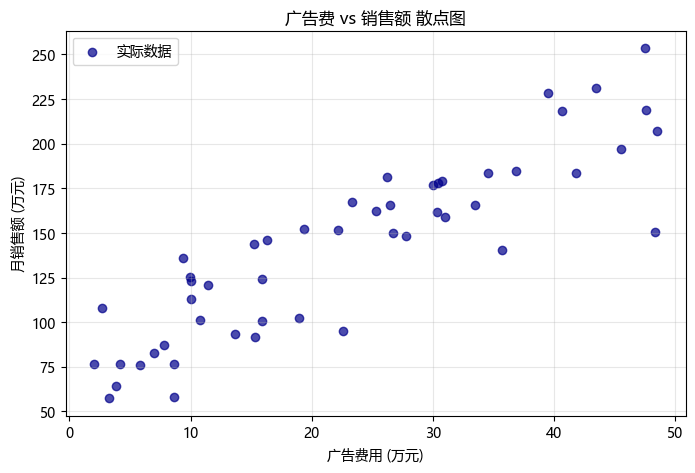


训练集样本数: 40，测试集样本数: 10

回归方程: 销售额 = 71.62 + 3.05 * 广告费

模型评估指标：
均方误差 (MSE): 468.62
均方根误差 (RMSE): 21.65 万元
决定系数 (R²): 0.7423


C:\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


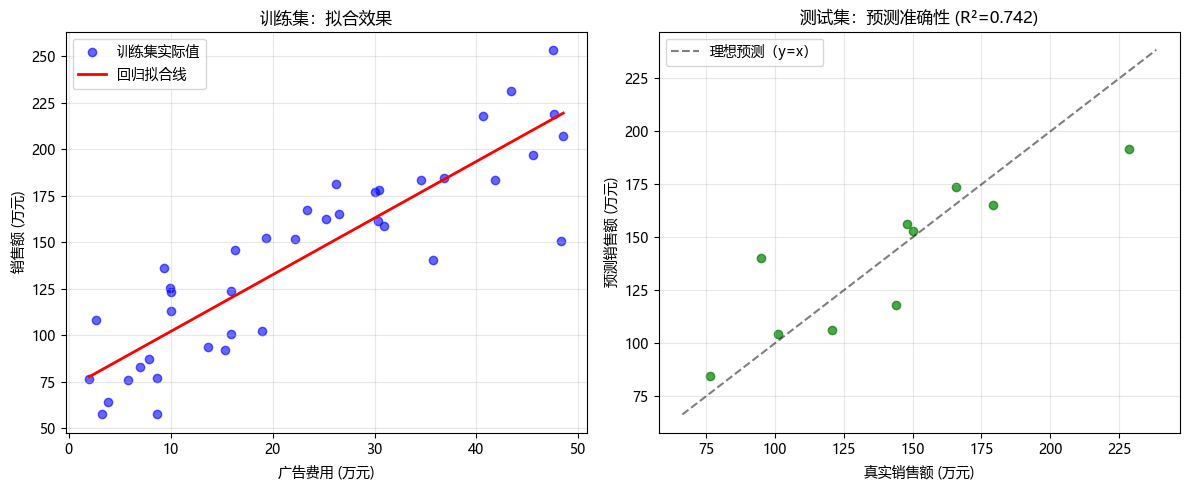


💡 业务决策建议：
若下月广告费投入 30 万元，预测销售额约为 163.01 万元


C:\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 设置中文字体（与之前案例保持一致）
plt.rc('font', **{'family': 'Microsoft YaHei, SimHei'})
plt.rcParams['axes.unicode_minus'] = False

# 1. 读取数据
df = pd.read_csv('广告费与销售额数据.csv')
print("数据统计描述：")
print(df.describe())

# 2. 绘制原始数据散点图（观察是否存在线性趋势）
plt.figure(figsize=(8, 5))
plt.scatter(df['Ad_Spend'], df['Sales'], alpha=0.7, color='darkblue', label='实际数据')
plt.xlabel('广告费用 (万元)')
plt.ylabel('月销售额 (万元)')
plt.title('广告费 vs 销售额 散点图')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# 3. 拆分训练集和测试集（有监督学习的标准流程）
X = df[['Ad_Spend']]  # 特征（必须为二维结构）
y = df['Sales']       # 目标值

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"\n训练集样本数: {len(X_train)}，测试集样本数: {len(X_test)}")

# 4. 创建线性回归模型并训练
model = LinearRegression()
model.fit(X_train, y_train)

# 输出模型参数（业务解读）
print(f"\n回归方程: 销售额 = {model.intercept_:.2f} + {model.coef_[0]:.2f} * 广告费")

# 5. 在测试集上进行预测
y_pred = model.predict(X_test)

# 6. 模型评估（关键指标）
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"\n模型评估指标：")
print(f"均方误差 (MSE): {mse:.2f}")
print(f"均方根误差 (RMSE): {rmse:.2f} 万元")
print(f"决定系数 (R²): {r2:.4f}")

# 7. 可视化回归结果（训练集拟合线 + 测试集预测对比）
plt.figure(figsize=(12, 5))

# 左图：训练集拟合线
plt.subplot(1, 2, 1)
plt.scatter(X_train, y_train, alpha=0.6, color='blue', label='训练集实际值')
# 绘制回归线（取广告费的最小到最大范围）
x_line = np.linspace(df['Ad_Spend'].min(), df['Ad_Spend'].max(), 100).reshape(-1, 1)
y_line = model.predict(x_line)
plt.plot(x_line, y_line, color='red', linewidth=2, label='回归拟合线')
plt.xlabel('广告费用 (万元)')
plt.ylabel('销售额 (万元)')
plt.title('训练集：拟合效果')
plt.legend()
plt.grid(alpha=0.3)

# 右图：测试集预测值与真实值对比
plt.subplot(1, 2, 2)
plt.scatter(y_test, y_pred, alpha=0.7, color='green')
# 添加理想对角线（y=x）
min_val = min(y_test.min(), y_pred.min()) - 10
max_val = max(y_test.max(), y_pred.max()) + 10
plt.plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.5, label='理想预测（y=x）')
plt.xlabel('真实销售额 (万元)')
plt.ylabel('预测销售额 (万元)')
plt.title(f'测试集：预测准确性 (R²={r2:.3f})')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('线性回归结果分析.png', dpi=300)
plt.show()

# 8. 实战预测：若下月计划投入 30 万广告费，预计销售额？
new_ad = np.array([[30]])
predicted_sales = model.predict(new_ad)
print(f"\n💡 业务决策建议：")
print(f"若下月广告费投入 {new_ad[0][0]} 万元，预测销售额约为 {predicted_sales[0]:.2f} 万元")

## 梯度下降算法分类 (Gradient Descent)

### 1.全梯度下降 FGD
每次迭代，使用全部样本的梯度值

### 2.小批量梯度下降 mini-batch
每次迭代时，随机选择并使用小批量样本的梯度值

### 3.随机平均梯度下降 SAG

### 4.随机梯度下降 SGD
每次迭代，随机选择并使用一个样本梯度值